# GeoGen AI — Clean Project Walkthrough

**Purpose:** explain and demonstrate the existing GeoGen AI project without starting a new training run.

This notebook uses the project files and saved Epoch 50 checkpoint already stored in Google Drive. It does **not** train the model or overwrite the live website checkpoint.





## 1. Connect Google Drive and locate the project

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import sys

PROJECT = Path('/content/drive/MyDrive/GeoGen-AI/GeoGen-AI')
if not PROJECT.exists():
    raise FileNotFoundError(
        f'Project folder not found: {PROJECT}. Check the folder location in Google Drive.'
    )

sys.path.insert(0, str(PROJECT))
print('Project folder:', PROJECT)
print('Project files found:', all((PROJECT / name).exists() for name in ['models.py', 'train_gan.py', 'app.py']))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI
Project files found: True


## 2. Check the runtime and required libraries
This is an environment check only. It does not start training.

In [2]:
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image

print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU is connected. That is fine for reviewing the saved model; do not start training.')

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
CUDA available: False
No GPU is connected. That is fine for reviewing the saved model; do not start training.


## 3. Check the EuroSAT dataset
The dataset should have 10 land-use class folders. This cell only checks the existing extracted dataset.

In [9]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/GeoGen-AI/GeoGen-AI/data/raw/EuroSAT_RGB.zip"
)
extract_path = Path("/content/geogen_data/raw")

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extraction completed!")

Dataset extraction completed!


In [10]:
DATA_DIR = Path('/content/geogen_data/raw/EuroSAT_RGB')
CLASS_NAMES = [
    'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
    'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake'
]

if not DATA_DIR.exists():
    print('Dataset is not currently extracted in this Colab runtime.')
    print('The saved model can still be demonstrated. Do not run a full training job.')
else:
    total = 0
    for class_name in CLASS_NAMES:
        folder = DATA_DIR / class_name
        count = sum(1 for p in folder.iterdir()
                    if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}) if folder.is_dir() else 0
        print(f'{class_name}: {count} images')
        total += count
    print('Total images found:', total)

AnnualCrop: 3000 images
Forest: 3000 images
HerbaceousVegetation: 3000 images
Highway: 2500 images
Industrial: 2500 images
Pasture: 2000 images
PermanentCrop: 2500 images
Residential: 3000 images
River: 2500 images
SeaLake: 3000 images
Total images found: 27000


## 4. Load the saved Epoch 50 checkpoint
This reads the staging checkpoint. It does not replace or modify the live website checkpoint.

In [5]:
import torch
from models import Generator

CHECKPOINT_PATH = (
   PROJECT / 'artifacts' / 'staging' / 'checkpoints'
/ 'conditional_dcgan_epoch50.pt.pt'
)
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(
        f'Saved checkpoint not found: {CHECKPOINT_PATH}. Check Google Drive before continuing.'
    )

checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=False)
epoch = checkpoint.get('epoch', 'unknown')
latent_dim = checkpoint['latent_dim']
class_names = checkpoint.get('class_names', CLASS_NAMES)

generator = Generator(latent_dim=latent_dim)
generator.load_state_dict(checkpoint['generator'])
generator.eval()

print('Checkpoint:', CHECKPOINT_PATH.name)
print('Checkpoint epoch:', epoch)
print('Latent dimension:', latent_dim)
print('Classes:', len(class_names))
print('Generator loaded successfully.')

Checkpoint: conditional_dcgan_epoch50.pt.pt
Checkpoint epoch: 50
Latent dimension: 128
Classes: 10
Generator loaded successfully.


## 5. Generate one example for each land-use class
This uses the saved model only. It does not train.

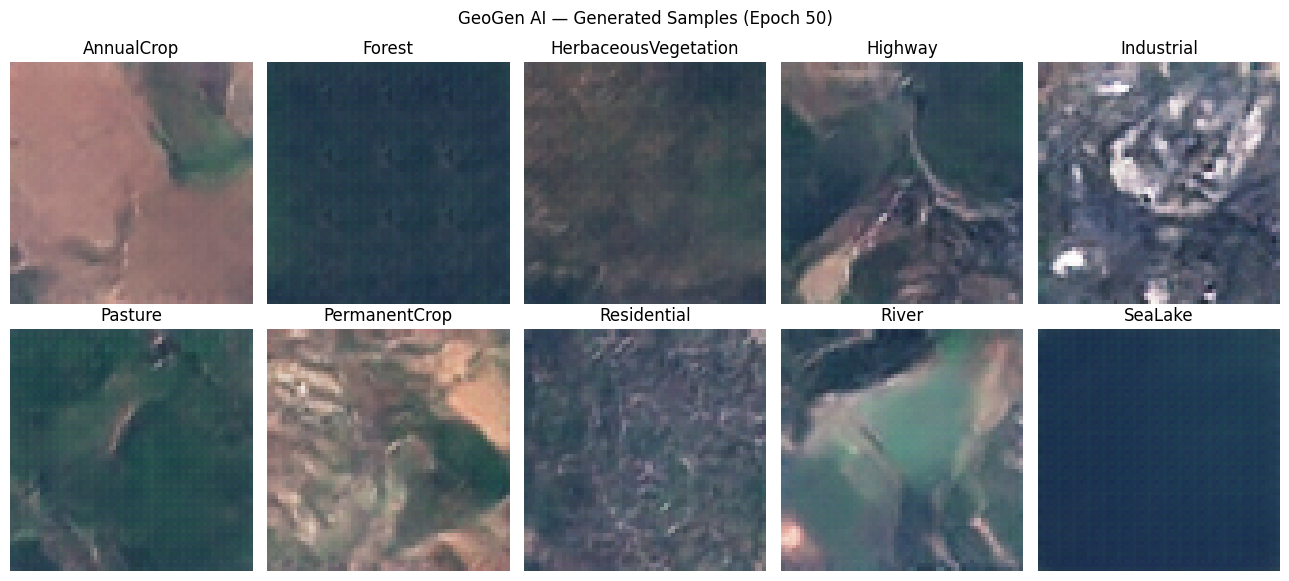

In [6]:
import matplotlib.pyplot as plt

torch.manual_seed(123)
noise = torch.randn(len(class_names), latent_dim)
labels = torch.arange(len(class_names))

with torch.no_grad():
    generated = generator(noise, labels).clamp(-1, 1)
    generated = (generated + 1) / 2

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i].permute(1, 2, 0).cpu().numpy())
    ax.set_title(class_names[i])
    ax.axis('off')
plt.suptitle(f'GeoGen AI — Generated Samples (Epoch {epoch})')
plt.tight_layout()
plt.show()

## 6. Compare generated images with real EuroSAT images (if available)
This optional comparison runs only when the dataset is present in the current Colab runtime.

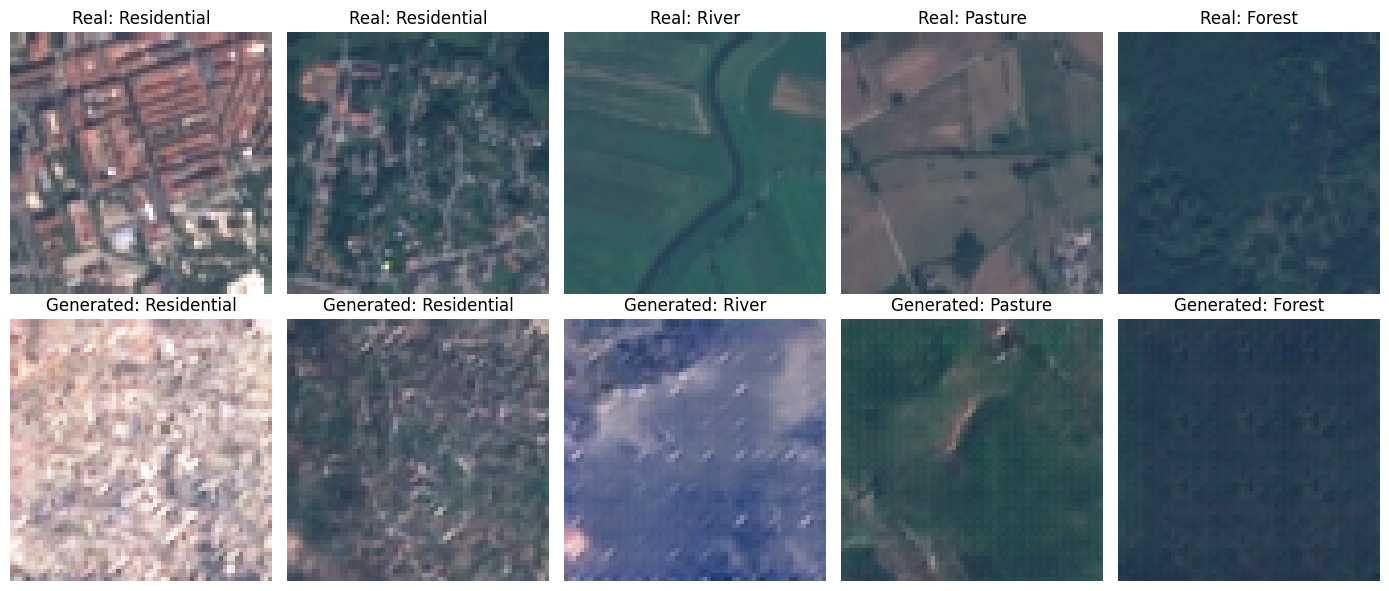

In [11]:
from torchvision.utils import make_grid

if DATA_DIR.exists():
    from dataset_utils import get_dataloaders
    train_loader, _ = get_dataloaders(DATA_DIR, batch_size=5, num_workers=2)
    real_images, real_labels = next(iter(train_loader))

    torch.manual_seed(321)
    noise = torch.randn(5, latent_dim)
    labels = real_labels[:5].cpu()

    with torch.no_grad():
        fake_images = generator(noise, labels).clamp(-1, 1)
        fake_images = (fake_images + 1) / 2

    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for i in range(5):
        real = ((real_images[i].cpu().permute(1, 2, 0) + 1) / 2).clamp(0, 1)
        axes[0, i].imshow(real)
        axes[0, i].set_title(f'Real: {class_names[labels[i].item()]}')
        axes[0, i].axis('off')

        axes[1, i].imshow(fake_images[i].permute(1, 2, 0).cpu().numpy())
        axes[1, i].set_title(f'Generated: {class_names[labels[i].item()]}')
        axes[1, i].axis('off')

    axes[0, 0].set_ylabel('REAL', fontsize=12)
    axes[1, 0].set_ylabel('GENERATED', fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: dataset is not extracted in this runtime. No training is needed for this step.')

## 7. Review saved training losses (if included in the checkpoint)
Loss curves are one diagnostic, but they do not by themselves prove that generated images are realistic.

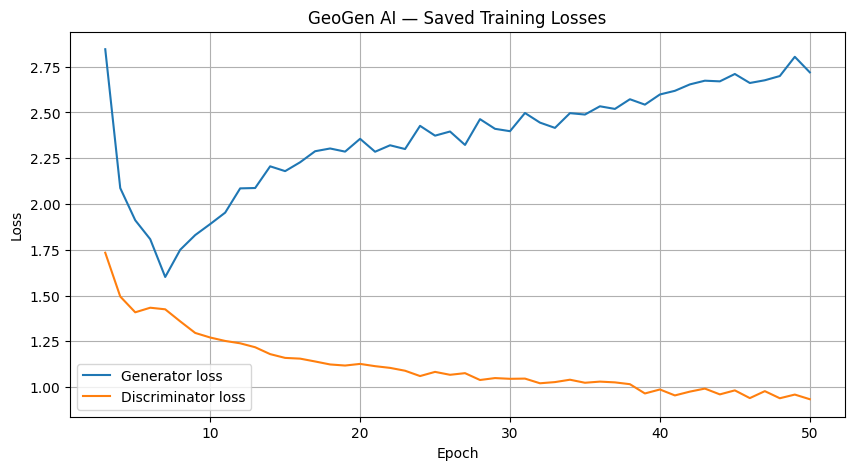

In [8]:
history = checkpoint.get('history', [])
if history:
    epochs = [row['epoch'] for row in history]
    g_losses = [row['generator_loss'] for row in history]
    d_losses = [row['discriminator_loss'] for row in history]

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, g_losses, label='Generator loss')
    plt.plot(epochs, d_losses, label='Discriminator loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('GeoGen AI — Saved Training Losses')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print('This checkpoint does not contain training history, so no loss graph is available.')

## 8. Project

- **Dataset:** EuroSAT RGB satellite images, organized into 10 land-use classes.
- **Model:** a Conditional DCGAN. The class label tells the generator which land-use category to attempt.
- **Training:** the generator learns to create images while the discriminator learns to distinguish generated images from real training images.
- **Output:** a saved generator checkpoint is loaded by the Streamlit app to create 64 × 64 RGB images.
- **Current limitation:** generated images are blurry and can look similar. Image quality and diversity need further evaluation before using them for serious data augmentation.

**Safety note:** This cleaned notebook intentionally contains no training command. It will not retrain the model when run from top to bottom.